# Placement Comparison Analysis
LLM-as-a-judge pairwise comparisons between the **semantic** ad placement and three static baselines (**first**, **middle**, **last**).

Each (query, ad, baseline) is judged twice: once with semantic shown first (`is_swapped=False`) and once with the baseline shown first (`is_swapped=True`).
That lets us separate genuine preference from the judge's position bias:

1. **Sample** - what was scored.
2. **Per-judgment win rate** - the raw rate, with 95% Wilson intervals.
3. **Position bias** - how often the judge simply picks whichever response it saw first.
4. **Order-debiased verdict** - per pair, did semantic win in both orders, lose in both, or split?
5. **Confidence** - win rate by the judge's stated confidence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#898781",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
SEMANTIC, BASELINE, SPLIT = "#2a78d6", "#eb6834", "#898781"
CONFIDENCE_COLORS = {"low": "#86b6ef", "medium": "#2a78d6", "high": "#104281"}
BASELINES = ["first", "middle", "last"]


def wilson(successes, n, z=1.96):
    """95% Wilson score interval for a proportion, as (low, high) in [0, 1]."""
    successes, n = np.asarray(successes, float), np.asarray(n, float)
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(frame, by, outcome):
    """Rate of a boolean `outcome` per group, in %, with Wilson 95% CI and n."""
    out = frame.groupby(by)[outcome].agg(wins="sum", n="count").reset_index()
    low, high = wilson(out["wins"], out["n"])
    out["rate_%"], out["ci_low_%"], out["ci_high_%"] = 100 * out["wins"] / out["n"], 100 * low, 100 * high
    return out


df = pd.read_csv("../../../data/evaluation/ad_placement_eval/placement_comparison_scores.csv")
df["baseline_pos"] = np.where(df["pos_1"] == "semantic", df["pos_2"], df["pos_1"])
df["semantic_won"] = df["winner_pos"] == "semantic"
df["first_shown_won"] = df["winner_pos"] == df["pos_1"]

## 1. Sample

In [2]:
sample = (
    df.groupby(["baseline_pos", "is_swapped"]).size().unstack("is_swapped")
    .rename(columns={False: "semantic shown first", True: "baseline shown first"})
    .reindex(BASELINES)
)
print(f"{len(df):,} judgments over {df['query_id'].nunique():,} queries")
print("duplicate (query, ad, pair, order) rows:", df.duplicated(["query_id", "ad_id", "pos_1", "pos_2", "is_swapped"]).sum())
display(sample)
display(df["confidence"].value_counts().rename("judgments").to_frame())

75,776 judgments over 12,630 queries
duplicate (query, ad, pair, order) rows: 0


is_swapped,semantic shown first,baseline shown first
baseline_pos,,
first,12630,12630
middle,12629,12629
last,12629,12629


,judgments
confidence,
high,62609
low,12261
medium,906


## 2. Per-judgment win rate
Share of individual judgments that semantic won. This mixes both presentation orders, so position bias largely cancels, but a split pair counts as one win and one loss.

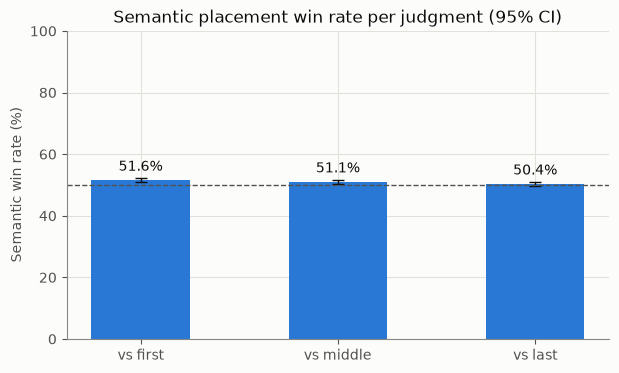

,wins,n,rate_%,ci_low_%,ci_high_%
baseline_pos,,,,,
first,13038,25260,51.62,51.00,52.23
middle,12902,25258,51.08,50.46,51.70
last,12725,25258,50.38,49.76,51.00


In [3]:
win_rates = rate_table(df, "baseline_pos", "semantic_won").set_index("baseline_pos").reindex(BASELINES)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(BASELINES))
ax.bar(x, win_rates["rate_%"], width=0.5, color=SEMANTIC)
ax.errorbar(x, win_rates["rate_%"],
            yerr=[win_rates["rate_%"] - win_rates["ci_low_%"], win_rates["ci_high_%"] - win_rates["rate_%"]],
            fmt="none", ecolor="#0b0b0b", capsize=4, linewidth=1)
for xi, rate in zip(x, win_rates["rate_%"]):
    ax.text(xi, rate + 3, f"{rate:.1f}%", ha="center", color="#0b0b0b")
ax.axhline(50, color="#52514e", linestyle="--", linewidth=1)
ax.set_xticks(x, [f"vs {b}" for b in BASELINES])
ax.set(ylim=(0, 100), ylabel="Semantic win rate (%)", title="Semantic placement win rate per judgment (95% CI)")
plt.show()

display(win_rates.round(2))

## 3. Position bias
If the judge had no order preference, the response shown first would win about half the time once placement quality is averaged over both orders.
A rate far from 50% means order, not placement, is driving many verdicts.

In [4]:
bias = rate_table(df, ["baseline_pos", "is_swapped"], "first_shown_won")
bias["shown_first"] = np.where(bias["is_swapped"], "baseline", "semantic")
overall_bias = df["first_shown_won"].mean() * 100
print(f"Overall: the first-shown response wins {overall_bias:.1f}% of judgments")
display(bias[["baseline_pos", "shown_first", "wins", "n", "rate_%", "ci_low_%", "ci_high_%"]].round(2))

Overall: the first-shown response wins 94.7% of judgments


,baseline_pos,shown_first,wins,n,rate_%,ci_low_%,ci_high_%
0,first,semantic,12345,12630,97.74,97.47,97.99
1,first,baseline,11937,12630,94.51,94.10,94.90
2,last,semantic,12226,12629,96.81,96.49,97.10
3,last,baseline,12130,12629,96.05,95.69,96.37
4,middle,semantic,11698,12629,92.63,92.16,93.07
5,middle,baseline,11425,12629,90.47,89.94,90.97


## 4. Order-debiased verdict
Pair each forward judgment with its swapped twin. Per (query, ad, baseline):
- **semantic wins** - semantic won in both orders
- **baseline wins** - baseline won in both orders
- **split** - the verdict flipped with the order (judge inconsistent; treated as a tie)

The **decisive win rate** is semantic wins / (semantic wins + baseline wins), tested against 50% with a two-sided sign test.

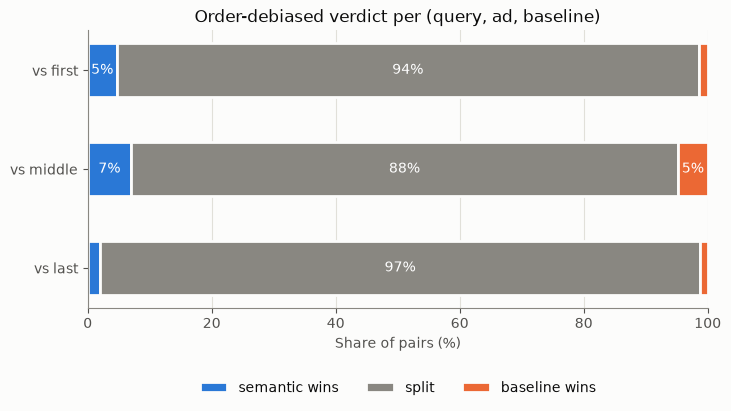

verdict,semantic wins,split,baseline wins,decisive,decisive_win_rate_%,ci_low_%,ci_high_%,split_%,sign_test_p
baseline_pos,,,,,,,,,
first,588,11862,180,768,76.6,73.4,79.4,93.9,2.59e-51
middle,880,11142,607,1487,59.2,56.7,61.7,88.2,1.51e-12
last,259,12207,163,422,61.4,56.6,65.9,96.7,3.43e-06


In [5]:
pairs = (
    df.pivot_table(index=["query_id", "ad_id", "baseline_pos"], columns="is_swapped",
                   values="semantic_won", aggfunc="first")
    .dropna(subset=[False, True])
    .reset_index()
)
forward, swapped = pairs[False].astype(bool), pairs[True].astype(bool)
pairs["verdict"] = np.select(
    [forward & swapped, ~forward & ~swapped],
    ["semantic wins", "baseline wins"], default="split",
)
VERDICTS = ["semantic wins", "split", "baseline wins"]
counts = pairs.groupby("baseline_pos")["verdict"].value_counts().unstack(fill_value=0).reindex(index=BASELINES, columns=VERDICTS)
shares = counts.div(counts.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(BASELINES))
for verdict, color in zip(VERDICTS, [SEMANTIC, SPLIT, BASELINE]):
    ax.barh(BASELINES, shares[verdict], left=left, color=color, height=0.55,
            edgecolor="#fcfcfb", linewidth=2, label=verdict)
    for y, (l, w) in enumerate(zip(left, shares[verdict])):
        if w >= 4:
            ax.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center", color="#ffffff")
    left += shares[verdict]
ax.invert_yaxis()
ax.set_yticks(range(len(BASELINES)), [f"vs {b}" for b in BASELINES])
ax.set(xlim=(0, 100), xlabel="Share of pairs (%)", title="Order-debiased verdict per (query, ad, baseline)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
plt.show()

decisive = counts.assign(decisive=counts["semantic wins"] + counts["baseline wins"])
low, high = wilson(decisive["semantic wins"], decisive["decisive"])
decisive["decisive_win_rate_%"] = 100 * decisive["semantic wins"] / decisive["decisive"]
decisive["ci_low_%"], decisive["ci_high_%"] = 100 * low, 100 * high
decisive["split_%"] = shares["split"]
decisive["sign_test_p"] = [binomtest(int(w), int(n)).pvalue for w, n in zip(decisive["semantic wins"], decisive["decisive"])]
with pd.option_context("display.float_format", "{:.3g}".format):
    display(decisive)

## 5. Win rate by confidence
Per-judgment semantic win rate, split by the judge's stated confidence. Check `n`: a level with few judgments gets a wide interval.

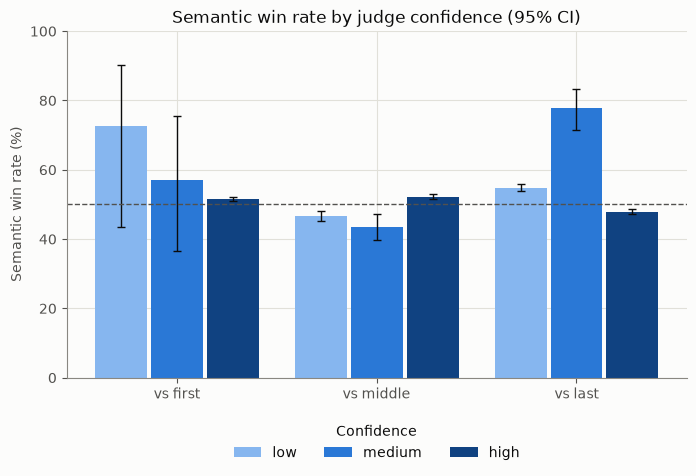

,baseline_pos,confidence,wins,n,rate_%,ci_low_%,ci_high_%
0,first,high,13018,25228,51.60,50.98,52.22
1,first,low,8,11,72.73,43.43,90.25
2,first,medium,12,21,57.14,36.55,75.53
3,last,high,8078,16866,47.90,47.14,48.65
4,last,low,4495,8197,54.84,53.76,55.91
5,last,medium,152,195,77.95,71.62,83.20
6,middle,high,10709,20515,52.20,51.52,52.88
7,middle,low,1893,4053,46.71,45.17,48.24
8,middle,medium,300,690,43.48,39.83,47.20


In [6]:
CONFIDENCE = ["low", "medium", "high"]
conf = rate_table(df, ["baseline_pos", "confidence"], "semantic_won")

fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.26
for i, level in enumerate(CONFIDENCE):
    sub = conf[conf["confidence"] == level].set_index("baseline_pos").reindex(BASELINES)
    xs = np.arange(len(BASELINES)) + (i - 1) * (width + 0.02)
    ax.bar(xs, sub["rate_%"], width=width, color=CONFIDENCE_COLORS[level], label=level)
    ax.errorbar(xs, sub["rate_%"], yerr=[sub["rate_%"] - sub["ci_low_%"], sub["ci_high_%"] - sub["rate_%"]],
                fmt="none", ecolor="#0b0b0b", capsize=3, linewidth=1)
ax.axhline(50, color="#52514e", linestyle="--", linewidth=1)
ax.set_xticks(range(len(BASELINES)), [f"vs {b}" for b in BASELINES])
ax.set(ylim=(0, 100), ylabel="Semantic win rate (%)", title="Semantic win rate by judge confidence (95% CI)")
ax.legend(title="Confidence", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.show()

display(conf.round(2))

## Findings (2026-11-04: 12,630 queries, 75,776 judgments)
- **The judge is dominated by position bias.** The response shown first wins **94.7%** of judgments (90-98% in every baseline x order cell), regardless of which placement it is.
- **So the raw ~50% win rates in section 2 are not evidence of a tie.** They mostly reflect the judge picking the first-shown response, with semantic and the baseline each shown first half the time.
- **Once both orders are paired, 88-97% of pairs split** (the verdict flips with the order). Only a small decisive set carries real signal.
- **Among decisive pairs, semantic is preferred over every baseline** (two-sided sign test p < 0.001 for each):
  - vs first: **76.6%** (95% CI 73.4-79.4, n=768)
  - vs middle: **59.2%** (95% CI 56.7-61.7, n=1,487)
  - vs last: **61.4%** (95% CI 56.6-65.9, n=422)
- **Stated confidence is not informative:** 83% of judgments are "high", and high-confidence judgments still track the presentation order.
- **Implication:** the placement judge (`DeepSeek-R1-Distill-Qwen-32B`) barely separates placements. Report the debiased decisive rate together with the split share, and consider a stronger judge, a tie option, or a prompt that de-emphasises order.